In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", "{:,.2f}".format)

In [6]:
df1 = pd.read_csv(r"C:\Users\haran\Documents\Infosys Springboard Internship\-AI-Powered-Multi-Agent-System-for-Market-Analysis-and-Research\multi-agent-stock-analyst\backend\Data\cleaned\cleaned_nse_top100.csv")

df1["date"] = pd.to_datetime(df1["date"])

df1 = df1.sort_values(["ticker", "date"])

print("Dataset shape:", df1.shape)
print("Total stocks:", df1["ticker"].nunique())

df1.head()

Dataset shape: (252625, 19)
Total stocks: 103


,date,open,high,low,close,volume,turnover,ticker,symbol,series,prev_close,last,vwap,trades,deliverable_volume,%deliverble,daily_return,price_range,price_change
0,2010-01-08,755.00,807.00,755.00,807.00,51.00,"3,998,995,000.00",ABBOTINDIA,ABBOTINDIA,EQ,783.75,807.00,784.12,NaN,50.00,0.98,NaN,52.00,52.00
1,2010-01-11,825.00,825.00,790.00,804.80,897.00,"71,212,650,000.00",ABBOTINDIA,ABBOTINDIA,EQ,807.00,804.80,793.90,NaN,697.00,0.78,-0.27,35.00,-20.20
2,2010-01-12,800.00,805.00,790.00,790.00,426.00,"34,052,605,000.00",ABBOTINDIA,ABBOTINDIA,EQ,804.80,790.00,799.36,NaN,401.00,0.94,-1.84,15.00,-10.00
3,2010-01-13,787.00,787.00,720.00,767.00,359.00,"27,231,290,000.00",ABBOTINDIA,ABBOTINDIA,EQ,790.00,767.00,758.53,NaN,164.00,0.46,-2.91,67.00,-20.00
4,2010-01-14,769.00,798.00,769.00,785.10,317.00,"25,097,850,000.00",ABBOTINDIA,ABBOTINDIA,EQ,767.00,785.10,791.73,NaN,122.00,0.38,2.36,29.00,16.10


In [7]:
df1["year"] = df1["date"].dt.year

annual_analysis = df1.groupby(
    ["ticker", "year"]
).agg(
    annual_turnover=("turnover", "sum"),
    average_close=("close", "mean"),
    first_close=("close", "first"),
    last_close=("close", "last"),
    trading_days=("date", "count")
).reset_index()

annual_analysis.head()

,ticker,year,annual_turnover,average_close,first_close,last_close,trading_days
0,ABBOTINDIA,2010,"208,267,314,440,000.00","1,080.35",807.00,"1,310.20",248
1,ABBOTINDIA,2011,"125,951,265,190,000.00","1,413.07","1,322.90","1,460.90",247
2,ABBOTINDIA,2012,"91,563,013,910,000.00","1,507.86","1,467.25","1,482.50",251
3,ABBOTINDIA,2013,"116,859,016,205,000.00","1,420.12","1,494.35","1,686.55",250
4,ABBOTINDIA,2014,"326,175,775,875,000.00","2,318.74","1,670.55","3,804.40",244


In [7]:
df=pd.read_csv(r"C:\Users\haran\Downloads\archive (3)\Indian Company Financial Dataset.csv")
print(df.head)

<bound method NDFrame.head of                  Company  Year    Sales  Other Mfr. Exp  Employee Cost  \
0        360 ONE WAM LTD  2018 1,705.14           78.05         390.84   
1        360 ONE WAM LTD  2019 1,578.47           97.73         332.69   
2        360 ONE WAM LTD  2020 1,520.77          167.28         374.41   
3        360 ONE WAM LTD  2021 1,654.32          145.31         410.73   
4        360 ONE WAM LTD  2022 2,071.81          222.83         592.87   
...                  ...   ...      ...             ...            ...   
8986  ZYDUS WELLNESS LTD  2022 2,009.10           46.38         164.37   
8987  ZYDUS WELLNESS LTD  2023 2,254.80           54.50         168.20   
8988  ZYDUS WELLNESS LTD  2024 2,327.80           62.80         194.20   
8989  ZYDUS WELLNESS LTD  2025 2,708.90           81.10         238.80   
8990  ZYDUS WELLNESS LTD  2026 3,961.00           94.30         315.00   

      Selling and admin  Other Expenses  Other Income  Depreciation  Interest  \


In [8]:
print("Dataset Shape:", df.shape)

print("\nAll Columns:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (8991, 65)

All Columns:
1. Company
2. Year
3. Sales
4. Other Mfr. Exp
5. Employee Cost
6. Selling and admin
7. Other Expenses
8. Other Income
9. Depreciation
10. Interest
11. Profit before tax
12. Tax
13. Net profit
14. Dividend Amount
15. Equity Share Capital
16. Reserves
17. Borrowings
18. Other Liabilities
19. Total Liabilities
20. Net Block
21. Capital Work in Progress
22. Investments
23. Other Assets
24. Total Assets
25. Receivables
26. Cash & Bank
27. Cash from Operating Activity
28. Cash from Investing Activity
29. Cash from Financing Activity
30. Net Cash Flow
31. Raw Material Cost
32. Change in Inventory
33. Inventory
34. Power and Fuel
35. Expenses
36. Operating Profit
37. Profit_Margin
38. Operating_Margin
39. ROE
40. ROA
41. Debt_to_Equity
42. Interest_Coverage
43. Working_Capital_Ratio
44. Asset_Utilization
45. Receivable_Ratio
46. Inventory_Ratio
47. Expense_Ratio
48. Depreciation_Ratio
49. Operating_CF_Ratio
50. Cash_to_Debt
51. Cash_Margin
52. Revenue_Gr

,Company,Year,Sales,Other Mfr. Exp,Employee Cost,Selling and admin,Other Expenses,Other Income,Depreciation,Interest,...,Reserve_Growth,Operating_CF_Growth,Receivable_Growth,Inventory_Growth,Cash_Growth,Revenue_CAGR_3Y,Profit_CAGR_3Y,Revenue_Volatility,Profit_Volatility,Operating_CF_Volatility
0,360 ONE WAM LTD,2018,"1,705.14",78.05,390.84,148.53,34.94,9.67,13.61,558.76,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,360 ONE WAM LTD,2019,"1,578.47",97.73,332.69,158.07,-0.49,0.86,21.51,431.08,...,0.57,-1.67,0.52,0.00,-0.63,0.00,0.00,89.57,3.97,"3,269.82"
2,360 ONE WAM LTD,2020,"1,520.77",167.28,374.41,110.01,3.83,5.77,41.02,501.59,...,0.03,-0.12,-0.18,-1.00,3.25,0.00,0.00,94.31,101.77,"2,607.50"
3,360 ONE WAM LTD,2021,"1,654.32",145.31,410.73,77.98,27.35,2.31,42.97,413.55,...,-0.06,-0.72,-0.07,0.00,-0.29,-0.01,-0.01,66.98,98.60,746.05
4,360 ONE WAM LTD,2022,"2,071.81",222.83,592.87,105.27,-6.16,5.89,41.74,369.85,...,0.07,1.01,0.18,0.00,0.22,0.09,0.16,287.45,188.65,586.59


In [9]:
print("Total Companies:", df["Company"].nunique())

print("\nFinancial Year Range:")
print(df["Year"].min(), "to", df["Year"].max())

print("\nRecords per Company:")
display(df.groupby("Company").size().describe())

print("\nDuplicate Company-Year Records:")
print(df.duplicated(["Company", "Year"]).sum())

print("\nMissing Values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

Total Companies: 999

Financial Year Range:
2006 to 2026

Records per Company:


count   999.00
mean      9.00
std       1.92
min       1.00
25%       9.00
50%      10.00
75%      10.00
max      10.00
dtype: float64


Duplicate Company-Year Records:
0

Missing Values:


Company                 0
Year                    0
Sales                   0
Other Mfr. Exp          0
Employee Cost           0
Selling and admin       0
Other Expenses          0
Other Income            0
Depreciation            0
Interest                0
Profit before tax       0
Tax                     0
Net profit              0
Dividend Amount         0
Equity Share Capital    0
Reserves                0
Borrowings              0
Other Liabilities       0
Total Liabilities       0
Net Block               0
dtype: int64

In [10]:
stock_df = pd.read_csv(
    r"C:\Users\haran\Documents\Infosys Springboard Internship\-AI-Powered-Multi-Agent-System-for-Market-Analysis-and-Research\multi-agent-stock-analyst\backend\Data\cleaned\cleaned_nse_top100.csv"
)

stock_symbols = sorted(stock_df["ticker"].unique())

financial_companies = sorted(df["Company"].unique())

print("Existing NSE Stocks:", len(stock_symbols))
print("Financial Dataset Companies:", len(financial_companies))

print("\nSample NSE Tickers:")
print(stock_symbols[:20])

print("\nSample Financial Company Names:")
print(financial_companies[:20])

Existing NSE Stocks: 103
Financial Dataset Companies: 999

Sample NSE Tickers:
['ABBOTINDIA', 'ACC', 'ADANIPORTS', 'ADANITRANS', 'AMBUJACEM', 'ASIANPAINT', 'AUROPHARMA', 'AXISBANK', 'BAJAJ-AUTO', 'BAJAJFINSV', 'BAJAJHLDNG', 'BAJFINANCE', 'BANDHANBNK', 'BANKBARODA', 'BERGEPAINT', 'BHARTIARTL', 'BIOCON', 'BOSCHLTD', 'BPCL', 'BRITANNIA']

Sample Financial Company Names:
['360 ONE WAM LTD', '3M INDIA LTD', '63 MOONS TECHNOLOGIES LTD', 'AADHAR HOUSING FINANCE LTD', 'AARTI DRUGS LTD', 'AARTI INDUSTRIES LTD', 'AARTI PHARMALABS LTD', 'ABB INDIA LTD', 'ABBOTT INDIA LTD', 'ACC LTD', 'ACME SOLAR HOLDINGS LTD', 'ACTION CONSTRUCTION EQUIPMENT LTD', 'ACUTAAS CHEMICALS LTD', 'ADANI ENERGY SOLUTIONS LTD', 'ADANI ENTERPRISES LTD', 'ADANI GREEN ENERGY LTD', 'ADANI PORTS & SPECIAL ECONOMIC ZONE LTD', 'ADANI POWER LTD', 'ADANI TOTAL GAS LTD', 'ADITYA BIRLA CAPITAL LTD']


In [13]:
financial_df=df.copy()

In [14]:
numeric_cols = financial_df.select_dtypes(
    include=np.number
).columns

zero_percentage = (
    (financial_df[numeric_cols] == 0).mean() * 100
).sort_values(ascending=False)

print("Columns with highest zero percentages:")
display(zero_percentage.head(25).round(2))

important_cols = [
    "Sales",
    "Operating Profit",
    "Profit before tax",
    "Net profit",
    "Borrowings",
    "Total Assets",
    "Total Liabilities",
    "Cash from Operating Activity",
    "ROE",
    "ROA",
    "Debt_to_Equity",
    "Profit_Margin",
    "Operating_Margin"
]

print("\nFinancial Statistics:")
display(financial_df[important_cols].describe().T)

print("\nRecords per year:")
display(
    financial_df.groupby("Year")["Company"]
    .nunique()
    .rename("Number of Companies")
    .to_frame()
)

sample_companies = financial_df["Company"].unique()[:5]

display(
    financial_df[
        financial_df["Company"].isin(sample_companies)
    ][[
        "Company",
        "Year",
        "Sales",
        "Operating Profit",
        "Net profit",
        "Borrowings",
        "ROE",
        "ROA"
    ]].sort_values(["Company", "Year"])
)

Columns with highest zero percentages:


Profit_CAGR_3Y             45.01
Revenue_CAGR_3Y            33.95
Dividend Amount            32.87
Change in Inventory        29.35
Inventory_Growth           27.88
Raw Material Cost          26.27
Inventory_Ratio            18.99
Inventory                  18.64
Receivable_Growth          17.57
Borrowing_Growth           17.47
Investments                14.49
Power and Fuel             14.48
Capital Work in Progress   12.73
Operating_CF_Growth        12.05
Revenue_Growth             11.87
Cash_Growth                11.57
Revenue_Volatility         11.50
Operating_CF_Volatility    11.42
Asset_Growth               11.41
Reserve_Growth             11.33
Profit_Growth              11.22
Profit_Volatility          11.13
Receivable_Ratio            7.32
Receivables                 7.04
Other Mfr. Exp              6.77
dtype: float64


Financial Statistics:


,count,mean,std,min,25%,50%,75%,max
Sales,"8,991.00","13,170.57","52,638.43",-35.77,905.65,"2,478.52","6,923.60","1,055,780.00"
Operating Profit,"8,991.00","1,327.69","6,109.98","-61,797.00",26.03,204.91,726.68,"114,027.98"
Profit before tax,"8,991.00","1,491.30","6,417.23","-61,797.00",66.33,238.01,784.95,"123,162.00"
Net profit,"8,991.00","1,064.19","4,804.78","-73,878.10",47.96,179.37,582.53,"83,298.78"
Borrowings,"8,991.00","26,961.93","204,042.80",0.00,70.94,417.90,"2,394.60","6,820,399.27"
Total Assets,"8,991.00","46,980.87","288,013.95",0.00,"1,252.26","3,387.25","11,621.44","8,321,175.98"
Total Liabilities,"8,991.00","46,980.87","288,013.95",0.00,"1,252.26","3,387.25","11,621.44","8,321,175.98"
Cash from Operating Activity,"8,991.00","1,254.10","9,121.00","-97,820.41",31.55,204.91,742.70,"192,113.00"
ROE,"8,991.00",-0.02,14.02,"-1,320.67",0.07,0.13,0.20,98.44
ROA,"8,991.00",-0.27,20.74,"-1,389.50",0.02,0.06,0.11,6.44



Records per year:


,Number of Companies
Year,
2006,2
2007,2
2008,1
2011,2
2012,2
2013,3
2014,6
2015,11
2016,37


,Company,Year,Sales,Operating Profit,Net profit,Borrowings,ROE,ROA
0,360 ONE WAM LTD,2018,"1,705.14",490.08,380.17,"6,966.33",0.20,0.04
1,360 ONE WAM LTD,2019,"1,578.47",498.43,374.55,"6,103.08",0.13,0.04
2,360 ONE WAM LTD,2020,"1,520.77",325.92,201.16,"8,838.10",0.07,0.02
3,360 ONE WAM LTD,2021,"1,654.32",484.92,369.19,"5,076.69",0.13,0.04
4,360 ONE WAM LTD,2022,"2,071.81",751.30,577.74,"5,807.58",0.19,0.05
5,360 ONE WAM LTD,2023,"2,056.65",850.29,657.93,"6,783.67",0.21,0.06
6,360 ONE WAM LTD,2024,"2,920.91","1,008.54",804.21,"9,471.93",0.23,0.05
7,360 ONE WAM LTD,2025,"3,683.87","1,346.82","1,015.30","11,160.20",0.14,0.05
8,360 ONE WAM LTD,2026,"4,361.62","1,576.88","1,216.17","15,931.31",0.12,0.04
9,3M INDIA LTD,2017,"2,362.98",351.78,240.76,9.78,0.20,0.12


In [15]:
# Sort financial records chronologically
model_df = financial_df.sort_values(
    ["Company", "Year"]
).copy()

# Get the following year's financial information
model_df["Next_Year"] = (
    model_df.groupby("Company")["Year"].shift(-1)
)

model_df["Next_Year_Net_Profit"] = (
    model_df.groupby("Company")["Net profit"].shift(-1)
)

# Keep only consecutive financial years
model_df = model_df[
    model_df["Next_Year"] == model_df["Year"] + 1
].copy()

# Create binary target
model_df["Target"] = (
    model_df["Next_Year_Net_Profit"] < model_df["Net profit"]
).astype(int)

# Display target distribution
print("Dataset after target creation:", model_df.shape)

print("\nTarget Distribution:")
display(
    model_df["Target"]
    .value_counts()
    .rename(index={0: "No Decline", 1: "Decline"})
)

print("\nTarget Percentage:")
display(
    (model_df["Target"].value_counts(normalize=True) * 100)
    .rename(index={0: "No Decline", 1: "Decline"})
    .round(2)
)

print("\nSample Target Records:")
display(
    model_df[[
        "Company",
        "Year",
        "Net profit",
        "Next_Year",
        "Next_Year_Net_Profit",
        "Target"
    ]].head(15)
)

Dataset after target creation: (7949, 68)

Target Distribution:


Target
No Decline    5349
Decline       2600
Name: count, dtype: int64


Target Percentage:


Target
No Decline   67.29
Decline      32.71
Name: proportion, dtype: float64


Sample Target Records:


,Company,Year,Net profit,Next_Year,Next_Year_Net_Profit,Target
0,360 ONE WAM LTD,2018,380.17,"2,019.00",374.55,1
1,360 ONE WAM LTD,2019,374.55,"2,020.00",201.16,1
2,360 ONE WAM LTD,2020,201.16,"2,021.00",369.19,0
3,360 ONE WAM LTD,2021,369.19,"2,022.00",577.74,0
4,360 ONE WAM LTD,2022,577.74,"2,023.00",657.93,0
5,360 ONE WAM LTD,2023,657.93,"2,024.00",804.21,0
6,360 ONE WAM LTD,2024,804.21,"2,025.00","1,015.30",0
7,360 ONE WAM LTD,2025,"1,015.30","2,026.00","1,216.17",0
9,3M INDIA LTD,2017,240.76,"2,018.00",310.54,0
10,3M INDIA LTD,2018,310.54,"2,019.00",322.99,0


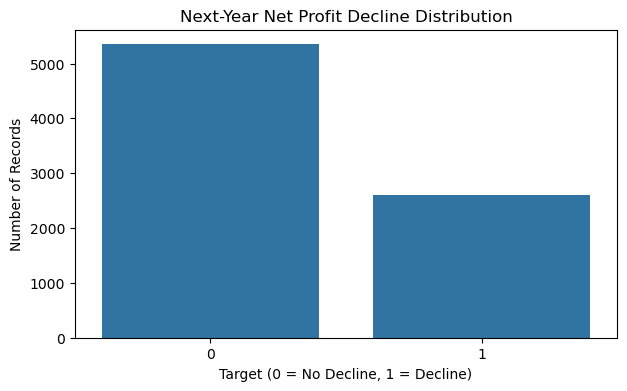

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=model_df,
    x="Target"
)

plt.title("Next-Year Net Profit Decline Distribution")
plt.xlabel("Target (0 = No Decline, 1 = Decline)")
plt.ylabel("Number of Records")

plt.show()

In [18]:
# Check financial ratios and extreme values

ratio_columns = [
    "Profit_Margin",
    "Operating_Margin",
    "ROE",
    "ROA",
    "Debt_to_Equity",
    "Interest_Coverage",
    "Working_Capital_Ratio",
    "Asset_Utilization",
    "Cash_to_Debt"
]

display(model_df[ratio_columns].describe().T)

# Check whether Total Assets and Total Liabilities
# are identical across all records

print(
    "Identical Assets and Liabilities:",
    (model_df["Total Assets"] == model_df["Total Liabilities"]).sum(),
    "out of",
    len(model_df)
)

# Check target distribution by year

print("\nTarget distribution by year:")
display(
    model_df.groupby("Year")["Target"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Decline_Rate"})
)

,count,mean,std,min,25%,50%,75%,max
Profit_Margin,"7,949.00",0.60,66.01,"-1,080.50",0.03,0.08,0.15,"5,676.31"
Operating_Margin,"7,949.00",0.46,66.79,"-1,080.50",0.02,0.10,0.19,"5,676.24"
ROE,"7,949.00",-0.04,14.91,"-1,320.67",0.07,0.13,0.20,98.44
ROA,"7,949.00",-0.32,22.06,"-1,389.50",0.02,0.06,0.11,6.44
Debt_to_Equity,"7,949.00",1.25,13.85,-514.20,0.05,0.35,1.05,531.23
Interest_Coverage,"7,949.00",67.30,"1,067.19","-1,445.81",0.87,4.34,21.23,"56,266.98"
Working_Capital_Ratio,"7,949.00",0.09,0.11,-0.00,0.02,0.04,0.11,0.78
Asset_Utilization,"7,949.00",1.86,1.61,-6.25,0.91,1.59,2.38,21.67
Cash_to_Debt,"7,949.00",95.35,"1,272.28",-0.00,0.06,0.24,1.77,"69,884.66"


Identical Assets and Liabilities: 7949 out of 7949

Target distribution by year:


,count,Decline_Rate
Year,,
2006,2,0.50
2007,1,0.00
2011,2,1.00
2012,2,0.50
2013,1,0.00
2014,4,0.75
2015,7,0.57
2016,29,0.14
2017,707,0.36


In [19]:
# Check missing values after target creation

print("Missing values in model_df:")
display(
    model_df.isnull().sum()
    .sort_values(ascending=False)
    .head(25)
)

# Check infinite values

numeric_df = model_df.select_dtypes(
    include=np.number
)

infinity_counts = pd.Series(
    np.isinf(numeric_df).sum(),
    name="Infinite Values"
).sort_values(ascending=False)

print("\nInfinite values:")
display(infinity_counts[infinity_counts > 0])

# Check financial columns with unusual values

check_columns = [
    "Sales",
    "Net profit",
    "Total Assets",
    "Borrowings",
    "ROE",
    "ROA",
    "Profit_Margin",
    "Debt_to_Equity",
    "Interest_Coverage",
    "Cash_to_Debt"
]

print("\nZero denominator-related checks:")

display(
    model_df[[
        "Sales",
        "Net profit",
        "Equity Share Capital",
        "Reserves",
        "Total Assets",
        "Borrowings",
        "Interest"
    ]].describe().T
)

Missing values in model_df:


Company                     0
Year                        0
Sales                       0
Other Mfr. Exp              0
Employee Cost               0
Selling and admin           0
Other Expenses              0
Other Income                0
Depreciation                0
Interest                    0
Profit before tax           0
Tax                         0
Net profit                  0
Dividend Amount             0
Equity Share Capital        0
Reserves                    0
Borrowings                  0
Other Liabilities           0
Total Liabilities           0
Net Block                   0
Capital Work in Progress    0
Investments                 0
Other Assets                0
Total Assets                0
Receivables                 0
dtype: int64


Infinite values:


Series([], Name: Infinite Values, dtype: int64)


Zero denominator-related checks:


,count,mean,std,min,25%,50%,75%,max
Sales,"7,949.00","12,559.19","50,287.94",-35.77,845.23,"2,345.14","6,648.04","962,820.00"
Net profit,"7,949.00",958.80,"4,433.45","-73,878.10",41.71,163.78,539.67,"77,561.34"
Equity Share Capital,"7,949.00",483.59,"2,215.37",0.00,16.41,42.38,147.87,"71,393.00"
Reserves,"7,949.00","7,455.31","30,999.35","-154,286.60",448.75,"1,340.47","3,977.97","829,668.00"
Total Assets,"7,949.00","44,478.75","269,303.09",0.00,"1,161.65","3,190.37","11,120.57","7,313,729.90"
Borrowings,"7,949.00","25,687.22","191,221.45",0.00,67.50,396.13,"2,334.78","6,050,755.27"
Interest,"7,949.00","1,352.82","8,758.59",-7.37,8.02,36.30,188.01,"300,943.34"


In [20]:
# Initial financial features

features = [
    "Sales",
    "Other Mfr. Exp",
    "Employee Cost",
    "Selling and admin",
    "Other Expenses",
    "Other Income",
    "Depreciation",
    "Interest",
    "Profit before tax",
    "Tax",
    "Net profit",
    "Borrowings",
    "Reserves",
    "Total Assets",
    "Investments",
    "Cash & Bank",
    "Operating Profit",
    "Cash from Operating Activity",
    "Cash from Investing Activity",
    "Cash from Financing Activity",
    "Net Cash Flow",
    "Profit_Margin",
    "Operating_Margin",
    "ROE",
    "ROA",
    "Debt_to_Equity",
    "Interest_Coverage",
    "Working_Capital_Ratio",
    "Asset_Utilization",
    "Cash_to_Debt"
]

# Remove early years with very limited company coverage
model_data = model_df[
    model_df["Year"] >= 2017
].copy()

# Chronological split
train_data = model_data[
    model_data["Year"] <= 2022
].copy()

test_data = model_data[
    model_data["Year"] >= 2023
].copy()

# Separate inputs and target
X_train = train_data[features]
y_train = train_data["Target"]

X_test = test_data[features]
y_test = test_data["Target"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining years:")
print(train_data["Year"].min(), "-", train_data["Year"].max())

print("\nTesting years:")
print(test_data["Year"].min(), "-", test_data["Year"].max())

print("\nTraining target distribution:")
display(y_train.value_counts())

print("\nTesting target distribution:")
display(y_test.value_counts())

print("\nFeature count:", len(features))

Training records: 4980
Testing records: 2921

Training years:
2017 - 2022

Testing years:
2023 - 2025

Training target distribution:


Target
0    3235
1    1745
Name: count, dtype: int64


Testing target distribution:


Target
0    2081
1     840
Name: count, dtype: int64


Feature count: 30


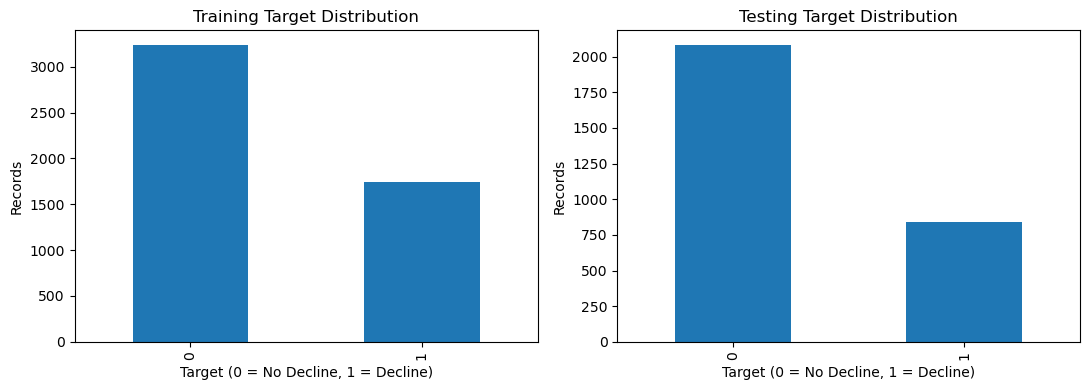

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

y_train.value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Training Target Distribution")
axes[0].set_xlabel("Target (0 = No Decline, 1 = Decline)")
axes[0].set_ylabel("Records")

y_test.value_counts().sort_index().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Testing Target Distribution")
axes[1].set_xlabel("Target (0 = No Decline, 1 = Decline)")
axes[1].set_ylabel("Records")

plt.tight_layout()
plt.show()

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import joblib

In [23]:
%pip install xgboost


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 251.4 kB/s eta 0:03:13
   ---------------------------------------- 0.5/48.9 MB 251.4 kB/s eta 0:03:13
 

In [25]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

In [26]:
pipelines = {}

for name, model in models.items():

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if name == "Logistic Regression":
        steps.append(
            ("scaler", RobustScaler())
        )

    steps.append(
        ("classifier", model)
    )

    pipelines[name] = Pipeline(steps)

In [27]:
results = []
trained_models = {}

for name, pipeline in pipelines.items():

    print(f"\nTraining: {name}")

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Probability predictions for ROC-AUC
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluate
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[name] = pipeline

    print("Accuracy:", round(accuracy, 4))
    print("F1 Score:", round(f1, 4))

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)
)


Training: Logistic Regression
Accuracy: 0.519
F1 Score: 0.4148

Training: Random Forest
Accuracy: 0.7011
F1 Score: 0.2184

Training: Gradient Boosting
Accuracy: 0.7145
F1 Score: 0.1934

Training: XGBoost
Accuracy: 0.6987
F1 Score: 0.2715


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.52,0.32,0.59,0.41,0.56
1,XGBoost,0.70,0.45,0.20,0.27,0.62
2,Random Forest,0.70,0.44,0.15,0.22,0.61
3,Gradient Boosting,0.71,0.52,0.12,0.19,0.61


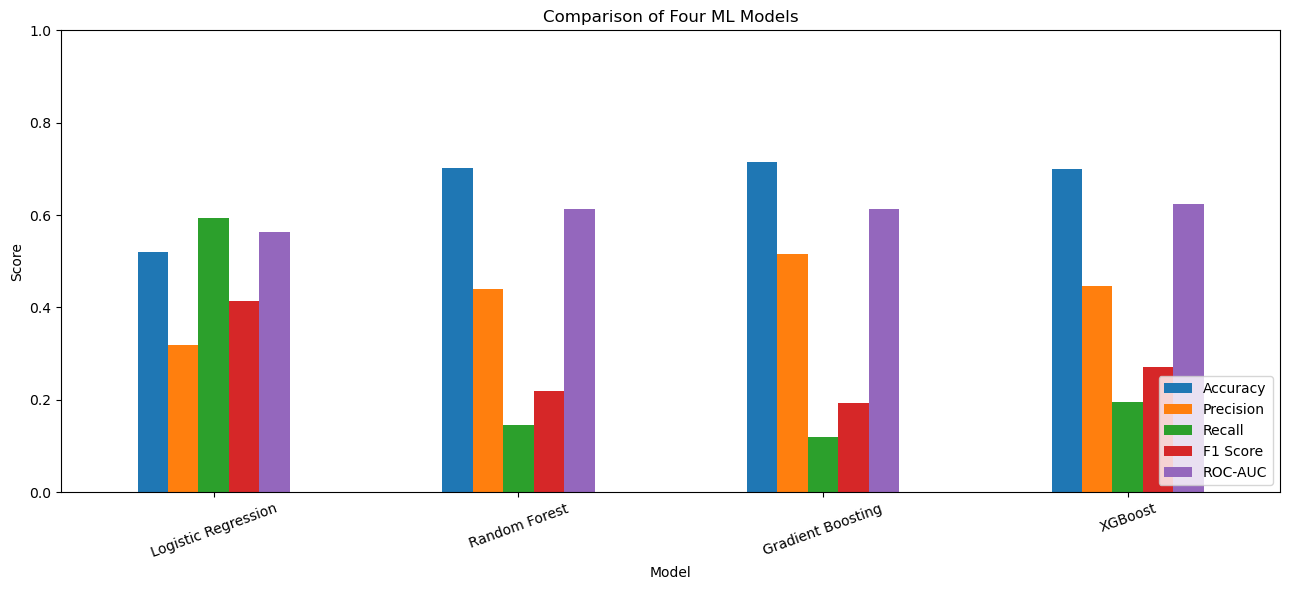

In [28]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Comparison of Four ML Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

  No Decline       0.75      0.49      0.59      2081
     Decline       0.32      0.59      0.41       840

    accuracy                           0.52      2921
   macro avg       0.53      0.54      0.50      2921
weighted avg       0.63      0.52      0.54      2921



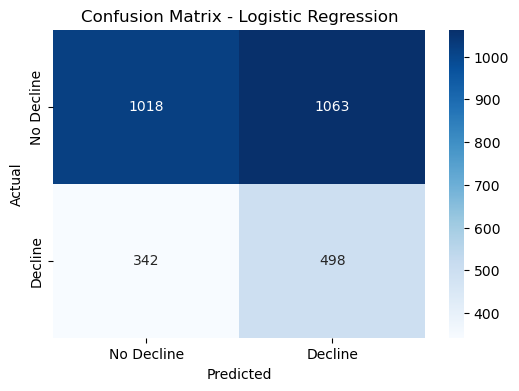

In [29]:
best_model_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

y_pred_best = best_model.predict(X_test)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["No Decline", "Decline"]
    )
)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Decline", "Decline"],
    yticklabels=["No Decline", "Decline"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")

plt.show()

In [30]:
joblib.dump(
    {
        "model": best_model,
        "features": features,
        "target_definition": (
            "1 if next consecutive year's net profit "
            "is lower than current year's net profit; otherwise 0"
        ),
        "model_name": best_model_name
    },
    "fundamental_analysis_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [31]:
import joblib

agent = joblib.load("fundamental_analysis_model.pkl")

print("Model loaded successfully!")
print("Available information:", agent.keys())

print("Model name:", agent["model_name"])
print("Number of features:", len(agent["features"]))
print("Target definition:", agent["target_definition"])

Model loaded successfully!
Available information: dict_keys(['model', 'features', 'target_definition', 'model_name'])
Model name: Logistic Regression
Number of features: 30
Target definition: 1 if next consecutive year's net profit is lower than current year's net profit; otherwise 0


In [32]:
company_name = "3M INDIA LTD"

company_data = financial_df[
    financial_df["Company"].str.upper() == company_name
].sort_values("Year")

latest_record = company_data.iloc[-1]

features = agent["features"]

input_data = pd.DataFrame(
    [latest_record[features]],
    columns=features
)

prediction = agent["model"].predict(input_data)[0]

probability = agent["model"].predict_proba(input_data)[0]

print("Company:", company_name)
print("Financial Year:", latest_record["Year"])

print(
    "Prediction:",
    "Profit Decline Expected" if prediction == 1
    else "No Profit Decline Expected"
)

print("No Decline Probability:", round(probability[0] * 100, 2), "%")
print("Decline Probability:", round(probability[1] * 100, 2), "%")

Company: 3M INDIA LTD
Financial Year: 2026
Prediction: No Profit Decline Expected
No Decline Probability: 55.51 %
Decline Probability: 44.49 %


In [48]:
financial_df.to_csv("Data",index=False)